# 06 Deep learning data pipeline

Phase 2 starts from the Phase 1 feature table, so the neural models see exactly the same information as LR and
XGBoost: same 35 inputs, same decision time (the evening before the flight), same split
(train Jan-Sep, validation Oct-Nov, test Dec).

This notebook prepares three kinds of input for the networks:
1. **32 numeric features**, imputed and standardised with training statistics only.
2. **3 categorical features** (carrier, origin, destination) as integer ids for the embedding layers.
   Id 0 is reserved for a category that never appeared in training.
3. **A 14-day sequence** of daily delay statistics before the flight date, for the temporal (GRU) branch.
   This is the new input of Phase 2. The project brief only allows a temporal model if the history is
   correctly ordered, so the end of this notebook has a leakage test for it.

Run the Phase 1 notebooks first: `02_feature_engineering.ipynb` writes `data/processed/features.pkl`,
which is the input here.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"font.size": 7, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from pathlib import Path

PHASE1_ROOT = Path("../ML_Phase-1").resolve()  # Phase 1 folder (ML_Phase-1)
ROOT = Path("..").resolve()                 # repository root (Phase 2)
PHASE1_DATA = PHASE1_ROOT / "data" / "processed"
PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results"
FIG_DIR = RESULTS_DIR / "figures"
for d in (PROCESSED_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEQ_LEN = 14      # days of history the GRU reads
MAX_SEQ_LEN = 28  # longest window tried in the ablation notebook, used for padding

## Load the Phase 1 features

In [3]:
with open(PHASE1_DATA / "feature_columns.json") as f:
    cols = json.load(f)
CAT_COLS, NUM_COLS = cols["cat"], cols["num"]
HISTORY_COLS = cols["groups"]["long_history"] + cols["groups"]["recent_history"]

df = pd.read_pickle(PHASE1_DATA / "features.pkl")
labelled = df[~df["no_arrival"]].reset_index(drop=True)
splits = {s: labelled[labelled["split"] == s].reset_index(drop=True) for s in ("train", "val", "test")}

print(f"{len(df):,} scheduled flights, {len(labelled):,} with an arrival label")
print(f"{len(CAT_COLS)} categorical + {len(NUM_COLS)} numeric inputs")
pd.DataFrame({s: {"flights": len(d), "delayed share": round(d["delayed"].mean(), 4),
                  "first day": d["date"].min().date(), "last day": d["date"].max().date()}
              for s, d in splits.items()}).T

336,776 scheduled flights, 327,346 with an arrival label
3 categorical + 32 numeric inputs


,flights,delayed share,first day,last day
train,244737,0.2498,2013-01-01,2013-09-30
val,55589,0.1782,2013-10-01,2013-11-30
test,27020,0.3355,2013-12-01,2013-12-31


## Numeric and categorical inputs

Medians, means, standard deviations and category vocabularies come from the **training months only**.
Missing values only occur on 1 January (no history yet), so median imputation is enough.

In [4]:
train = splits["train"]
medians = train[NUM_COLS].median()
filled = train[NUM_COLS].fillna(medians)
means, stds = filled.mean(), filled.std().replace(0, 1)

# id 0 = unknown category (a destination that never appears in training)
vocab = {c: {v: i + 1 for i, v in enumerate(sorted(train[c].unique()))} for c in CAT_COLS}


def encode_numeric(d):
    x = (d[NUM_COLS].fillna(medians) - means) / stds
    return x.to_numpy(dtype=np.float32)


def encode_categories(d):
    return np.stack([d[c].map(vocab[c]).fillna(0).to_numpy(dtype=np.int64) for c in CAT_COLS], axis=1)


{c: len(v) for c, v in vocab.items()}

{'carrier': 16, 'origin': 3, 'dest': 103}

In [5]:
unknown = {s: {c: int((encode_categories(d)[:, i] == 0).sum()) for i, c in enumerate(CAT_COLS)}
           for s, d in splits.items()}
pd.DataFrame(unknown)

,train,val,test
carrier,0,0,0
origin,0,0,0
dest,0,1,0


## Daily history for the temporal branch

For every day we summarise what happened at the three levels that matter for a flight:

| Level | Daily values |
|---|---|
| whole system | delay rate, mean arrival delay, cancellation share |
| origin airport (EWR/JFK/LGA) | delay rate, mean arrival delay, cancellation share, number of departures |
| carrier | delay rate, cancellation share (shrunk towards the system rate, small carriers have few flights) |

The sequence for a flight on day $d$ is the values of days $d-14, \dots, d-1$, ordered in time.
Days before 1 January do not exist; they are zero-padded and marked with a `valid` flag of 0.
The Phase 1 features already summarise this history (7-day and previous-day rates); the GRU gets the full
ordered trajectory instead, so it can learn things like "delays have been building up for three days".

In [6]:
DAYS = pd.date_range("2013-01-01", "2013-12-31")
ORIGINS = sorted(vocab["origin"], key=vocab["origin"].get)
N_CARRIER = len(vocab["carrier"]) + 1
CARRIER_SHRINK = 10   # pseudo-flights pulling a carrier's daily rate towards the system rate
SEQ_FEATURES = ["sys_rate", "sys_mean_delay", "sys_cancel",
                "origin_rate", "origin_mean_delay", "origin_cancel", "origin_volume",
                "carrier_rate", "carrier_cancel", "valid"]


def daily_stats(flights, keys):
    d = flights.assign(n_obs=(~flights["no_arrival"]).astype(int),
                       late=flights["delayed"].where(~flights["no_arrival"], 0),
                       delay_min=flights["arr_delay"].fillna(0),
                       cancelled=flights["no_arrival"].astype(int))
    g = d.groupby(keys + ["date"])[["n_obs", "late", "delay_min", "cancelled"]].sum()
    g["n_sched"] = d.groupby(keys + ["date"]).size()
    return g


def build_daily(flights):
    """Array [origin, carrier, day, feature] with the statistics of each calendar day (no shift yet)."""
    out = np.zeros((len(ORIGINS), N_CARRIER, len(DAYS), len(SEQ_FEATURES)), dtype=np.float32)

    s = daily_stats(flights.assign(_all="all"), ["_all"]).droplevel(0).reindex(DAYS)
    sys_rate = (s["late"] / s["n_obs"]).to_numpy()
    sys_cancel = (s["cancelled"] / s["n_sched"]).to_numpy()
    out[..., 0] = sys_rate
    out[..., 1] = (s["delay_min"] / s["n_obs"]).to_numpy() / 60
    out[..., 2] = sys_cancel

    o = daily_stats(flights, ["origin"])
    for i, name in enumerate(ORIGINS):
        oi = o.loc[name].reindex(DAYS)
        out[i, :, :, 3] = (oi["late"] / oi["n_obs"]).to_numpy()
        out[i, :, :, 4] = (oi["delay_min"] / oi["n_obs"]).to_numpy() / 60
        out[i, :, :, 5] = (oi["cancelled"] / oi["n_sched"]).to_numpy()
        out[i, :, :, 6] = oi["n_sched"].to_numpy() / 100

    c = daily_stats(flights, ["carrier"])
    out[:, 0, :, 7] = sys_rate          # unknown carrier: fall back to the system rate
    out[:, 0, :, 8] = sys_cancel
    for name, j in vocab["carrier"].items():
        cj = c.loc[name].reindex(DAYS).fillna(0) if name in c.index.get_level_values(0) else None
        if cj is None:
            out[:, j, :, 7], out[:, j, :, 8] = sys_rate, sys_cancel
            continue
        out[:, j, :, 7] = ((cj["late"] + CARRIER_SHRINK * sys_rate) / (cj["n_obs"] + CARRIER_SHRINK)).to_numpy()
        out[:, j, :, 8] = ((cj["cancelled"] + CARRIER_SHRINK * sys_cancel)
                           / (cj["n_sched"] + CARRIER_SHRINK)).to_numpy()
    out[..., 9] = 1.0
    return np.nan_to_num(out)


daily_raw = build_daily(df)
daily_raw.shape

(3, 17, 365, 10)

Standardise each daily value with the mean and standard deviation of the **training days**, then put
`MAX_SEQ_LEN` zero days in front (the padding before 1 January, `valid = 0`).

In [7]:
train_days = DAYS <= "2013-09-30"
flat = daily_raw[:, :, train_days, :-1].reshape(-1, len(SEQ_FEATURES) - 1)
seq_mean, seq_std = flat.mean(axis=0), flat.std(axis=0)
seq_std[seq_std == 0] = 1


def pad_and_scale(daily):
    scaled = daily.copy()
    scaled[..., :-1] = (scaled[..., :-1] - seq_mean) / seq_std
    pad = np.zeros(scaled.shape[:2] + (MAX_SEQ_LEN, scaled.shape[3]), dtype=np.float32)
    return np.concatenate([pad, scaled], axis=2)


daily = pad_and_scale(daily_raw)


def day_index(d):
    return (d["date"] - DAYS[0]).dt.days.to_numpy()


def sequences(daily_padded, origin_idx, carrier_idx, days, length=SEQ_LEN):
    """History of days d-length .. d-1 for each flight (same gather the networks use)."""
    steps = days[:, None] + MAX_SEQ_LEN - length + np.arange(length)[None, :]
    return daily_padded[origin_idx[:, None], carrier_idx[:, None], steps]

A look at what the GRU sees: the delay rate at each airport, day by day. December (grey area) is far worse
than October-November, which is the distribution shift Phase 1 already found.

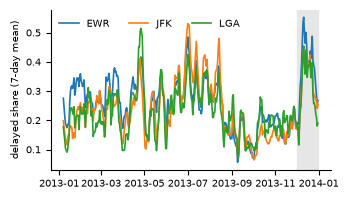

In [8]:
fig, ax = plt.subplots(figsize=(3.5, 2.0))
for i, name in enumerate(ORIGINS):
    ax.plot(DAYS, pd.Series(daily_raw[i, 1, :, 3]).rolling(7).mean(), label=name, lw=1.2)
ax.axvspan(pd.Timestamp("2013-12-01"), DAYS[-1], color="0.9", zorder=0)
ax.set(ylabel="delayed share (7-day mean)")
ax.legend(frameon=False, ncol=3)
fig.tight_layout()
fig.savefig(FIG_DIR / "daily_origin_rate.pdf")
plt.show()

## Leakage test for the sequences

Same idea as the Phase 1 test: if the sequence of a flight on day $D$ only uses earlier days, then changing
every outcome from day $D$ onwards must not change any sequence of a flight on day $D$ or before.
We overwrite all outcomes from 10 February with random values, rebuild the daily table and compare.

In [9]:
CUTOFF = pd.Timestamp("2013-02-10")


def scramble_outcomes(flights, from_date):
    flights = flights.copy()
    rng = np.random.default_rng(0)
    future = flights["date"] >= from_date
    flights.loc[future, "arr_delay"] = rng.normal(60, 80, future.sum())
    flights.loc[future, "no_arrival"] = rng.random(future.sum()) < 0.3
    flights.loc[future & flights["no_arrival"], "arr_delay"] = np.nan
    flights["delayed"] = (flights["arr_delay"] >= 15).astype(int)
    return flights


def all_sequences(daily_padded, flights):
    cat = encode_categories(flights)
    origin_idx = cat[:, 1] - 1
    return sequences(daily_padded, origin_idx, cat[:, 0], day_index(flights), MAX_SEQ_LEN)


def sequence_leakage_check(build):
    original = all_sequences(pad_and_scale(build(df)), labelled)
    scrambled = all_sequences(pad_and_scale(build(scramble_outcomes(df, CUTOFF))), labelled)
    upto = (labelled["date"] <= CUTOFF).to_numpy()
    assert np.array_equal(original[upto], scrambled[upto]), "sequences up to the cutoff changed"
    later = (labelled["date"] > CUTOFF).to_numpy()
    assert not np.array_equal(original[later], scrambled[later]), "scramble had no effect"
    return upto.sum()


n = sequence_leakage_check(build_daily)
print(f"passed: {n:,} flights up to {CUTOFF.date()} have identical 28-day sequences")

passed: 33,936 flights up to 2013-02-10 have identical 28-day sequences


Check that the test can actually fail: a deliberately leaky version where the sequence ends **on** the flight
day instead of the day before.

In [10]:
def build_daily_leaky(flights):
    return np.roll(build_daily(flights), -1, axis=2)   # day d now holds the values of day d+1


try:
    sequence_leakage_check(build_daily_leaky)
    print("PROBLEM: the leaky version was not detected")
except AssertionError as e:
    print("leaky version detected as expected:", e)

leaky version detected as expected: sequences up to the cutoff changed


## Save the network inputs

In [11]:
arrays = {"daily": daily}
for s, d in splits.items():
    cat = encode_categories(d)
    arrays[f"{s}_num"] = encode_numeric(d)
    arrays[f"{s}_cat"] = cat
    arrays[f"{s}_day"] = day_index(d)
    arrays[f"{s}_seq_origin"] = cat[:, 1] - 1
    arrays[f"{s}_y"] = d["delayed"].to_numpy(dtype=np.float32)
    arrays[f"{s}_id"] = d["id"].to_numpy()
np.savez_compressed(PROCESSED_DIR / "dl_inputs.npz", **arrays)

history_idx = [NUM_COLS.index(c) for c in HISTORY_COLS]
with open(PROCESSED_DIR / "dl_preprocessing.json", "w") as f:
    json.dump({"num_cols": NUM_COLS, "cat_cols": CAT_COLS, "history_idx": history_idx,
               "vocab": vocab, "medians": medians.to_dict(), "means": means.to_dict(), "stds": stds.to_dict(),
               "seq_features": SEQ_FEATURES, "seq_len": SEQ_LEN, "max_seq_len": MAX_SEQ_LEN,
               "seq_mean": seq_mean.tolist(), "seq_std": seq_std.tolist()}, f, indent=2)

print({k: v.shape for k, v in arrays.items() if k.startswith("train") or k == "daily"})

{'daily': (3, 17, 393, 10), 'train_num': (244737, 32), 'train_cat': (244737, 3), 'train_day': (244737,), 'train_seq_origin': (244737,), 'train_y': (244737,), 'train_id': (244737,)}


## Inputs for the hybrid model: XGBoost leaf ids

Notebook 08 feeds the leaves of the Phase 1 XGBoost into a network. We extract them here because XGBoost and
PyTorch cannot run in the same Python process on macOS (each loads its own OpenMP library and the kernel
crashes), and this notebook does not use PyTorch.

`pred_leaf=True` gives, for each flight and each of the 308 trees kept by early stopping, the id of the leaf
the flight lands in. Tree $t$'s node ids are below 32 (depth 4), so `32 * t + node` is unique over all trees.
The XGBoost model is loaded unchanged from Phase 1 (`models/xgb.json`, trained on Jan-Sep only).

In [12]:
import xgboost
from xgboost import XGBClassifier

PHASE1_MODELS = PHASE1_ROOT / "models"
with open(PHASE1_MODELS / "categories.json") as f:
    xgb_categories = json.load(f)

xgb = XGBClassifier()
xgb.load_model(PHASE1_MODELS / "xgb.json")
N_TREES = xgb.best_iteration + 1


def to_xgb_frame(d):
    X = d[CAT_COLS + NUM_COLS].copy()
    for c in CAT_COLS:
        X[c] = pd.Categorical(X[c].where(X[c].isin(xgb_categories[c])), categories=xgb_categories[c])
    return X


leaf_arrays = {}
for s, d in splits.items():
    X = to_xgb_frame(d)
    leaves = xgb.get_booster().predict(xgboost.DMatrix(X, enable_categorical=True), pred_leaf=True,
                                       iteration_range=(0, N_TREES)).astype(np.int64)
    leaf_arrays[f"{s}_leaf"] = leaves + 32 * np.arange(N_TREES)[None, :]
    leaf_arrays[f"{s}_p_xgb"] = xgb.predict_proba(X)[:, 1]

# the XGBoost scores must be exactly the Phase 1 raw predictions
for s in ("val", "test"):
    p1 = pd.read_pickle(PHASE1_DATA / f"predictions_{s}.pkl")
    assert np.array_equal(p1["id"].to_numpy(), splits[s]["id"].to_numpy())
    assert np.allclose(p1["p_xgb_raw"].to_numpy(), leaf_arrays[f"{s}_p_xgb"])

np.savez_compressed(PROCESSED_DIR / "xgb_leaves.npz", n_trees=N_TREES, **leaf_arrays)
print(f"{N_TREES} trees, {len(np.unique(leaf_arrays['train_leaf'])):,} distinct leaves used in training")

308 trees, 2,405 distinct leaves used in training
